# 🗄️ Archiviazione Vettoriale

**Argomenti trattati:**
1. Cosa sono gli embedding e come crearli
2. Come archiviare embedding in ChromaDB
3. Ricerca per similarità (similarity search)
4. Ranking dei risultati
5. Algoritmi di ricerca vettoriale usati da ChromaDB
6. Confronto tra diversi approcci di ricerca

---
> **Ambiente:** assicurati di aver attivato il virtualenv e installato le dipendenze (vedi `setup.txt`).

Creazione virtualenv: python3 -m venv .venv <br>
Usa vscode e attivalo selezionando il kernel il alto a destra <br>

> Esegui la cella di installazione qui sotto prima di procedere.

## 📦 Installazione delle dipendenze

In [1]:
# Esegui questa cella UNA SOLA VOLTA per installare le librerie necessarie
%pip install chromadb sentence-transformers numpy scikit-learn matplotlib

     ---------------------------------------- 0.0/52.0 kB ? eta -:--:--
     ---------------------------------------- 52.0/52.0 kB 2.8 MB/s eta 0:00:00
     ---------------------------------------- 0.0/43.1 kB ? eta -:--:--
     ---------------------------------------- 43.1/43.1 kB 2.1 MB/s eta 0:00:00
  Using cached aiohttp-3.14.3-cp311-cp311-win_amd64.whl.metadata (8.5 kB)
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/23.5 MB 5.2 MB/s eta 0:00:05
    --------------------------------------- 0.5/23.5 MB 6.2 MB/s eta 0:00:04
   - -------------------------------------- 0.7/23.5 MB 5.2 MB/s eta 0:00:05
   - -------------------------------------- 1.1/23.5 MB 5.7 MB/s eta 0:00:04
   -- ------------------------------------- 1.5/23.5 MB 6.3 MB/s eta 0:00:04
   --- ------------------------------------ 1.8/23.5 MB 6.9 MB/s eta 0:00:04
   --- ------------------------------------ 2.1/23.5 MB 6.4 MB/s eta 0:00:04
   ---- -----


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


---
# PARTE 1 — Esempi Guidati
---

## 1. Cosa sono gli Embedding?

Un **embedding** è una rappresentazione numerica (vettore) di un testo.  
Testi semanticamente simili producono vettori vicini nello spazio ad alta dimensione.

```
"gatto"   → [0.12, -0.43, 0.87, ...]
"felino"  → [0.11, -0.41, 0.85, ...]   ← molto vicino a "gatto"
"aereo"   → [-0.90, 0.33, -0.12, ...]  ← lontano da entrambi
```

Il modello che useremo è `all-MiniLM-L6-v2` (384 dimensioni), leggero e scaricabile gratuitamente da HuggingFace.

In [1]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Carica il modello (il download avviene automaticamente la prima volta)
model = SentenceTransformer("all-MiniLM-L6-v2")

frasi = [
    "Il gatto dorme sul divano.",
    "Un felino riposa sul sofà.",
    "L'aereo atterra all'aeroporto.",
]

# Genera gli embedding
vettori = model.encode(frasi)

print(f"\nNumero di frasi   : {len(frasi)}")
print(f"Dimensioni vettore: {vettori.shape[1]}")
print(f"\nPrimo vettore (prime 8 dimensioni):\n{vettori[0][:8]}")

c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\.venv\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (6.0.0.post1)/charset_normalizer (3.5.1) doesn't match a supported version!
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Numero di frasi   : 3
Dimensioni vettore: 384

Primo vettore (prime 8 dimensioni):
[-0.05954063  0.0171099  -0.03549254  0.00316507 -0.06842778  0.01808946
  0.07678527  0.03983127]


### 1.1 Similarità coseno

La **similarità coseno** misura l'angolo tra due vettori:

$$\text{cosine\_sim}(A, B) = \frac{A \cdot B}{\|A\| \cdot \|B\|}$$

- Valore **1.0** → vettori identici
- Valore **0.0** → vettori ortogonali (nessuna relazione)
- Valore **-1.0** → vettori opposti

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

#Genero la matrice di similarità tra i vettori
sim_matrix = cosine_similarity(vettori)

print("Matrice di similarità coseno:\n")

etichette = ["gatto", "felino", "aereo"]
header = f"{'':>10}" + "".join(f"{e:>10}" for e in etichette) 
print(header)

for i, riga in enumerate(sim_matrix):
    print(f"{etichette[i]:>10}" + "".join(f"{v:10.4f}" for v in riga))

Matrice di similarità coseno:

               gatto    felino     aereo
     gatto    1.0000    0.5252    0.3670
    felino    0.5252    1.0000    0.4292
     aereo    0.3670    0.4292    1.0000


---
## 2. ChromaDB — Archiviazione degli Embedding

**ChromaDB** è un database vettoriale open-source pensato per applicazioni AI.  
Permette di:
- **Archiviare** documenti con i loro embedding
- **Interrogare** la collezione con una query testuale
- **Filtrare** i risultati per metadati

### Architettura ChromaDB

```
Client
  └── Collection  (es. "articoli_scienza")
        ├── documento 1  → embedding + metadati
        ├── documento 2  → embedding + metadati
        └── ...
```

In [ ]:
# Importa cast, utile per indicare a un controllo statico dei tipi
# che l'oggetto ef va considerato un'EmbeddingFunction.
from typing import cast

# Importa la libreria ChromaDB, che gestisce il database vettoriale.
import chromadb

# Importa una funzione che crea embedding usando un modello Sentence Transformers.
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

# Importa il tipo usato da ChromaDB per rappresentare una funzione di embedding.
from chromadb.api.types import EmbeddingFunction


# Crea un client ChromaDB in memoria: i dati non vengono salvati su disco
# e in genere si perdono quando il processo termina.
client = chromadb.Client()


# Crea la funzione che trasformerà i testi in vettori numerici.
ef = SentenceTransformerEmbeddingFunction(
    # Se non è già disponibile in locale, il modello viene scaricato
    # al primo utilizzo.
    model_name="all-MiniLM-L6-v2"
)


# Crea una collezione chiamata "articoli_scienza" oppure recupera quella
# omonima se esiste già nel client.
collezione = client.get_or_create_collection(
    # Nome identificativo della collezione.
    name="articoli_scienza",

    # Dice a ChromaDB quale funzione usare per generare gli embedding
    # quando aggiunge o cerca documenti. cast() aiuta il controllo dei tipi:
    # non modifica l'oggetto ef durante l'esecuzione.
    embedding_function=cast(EmbeddingFunction, ef),

    # Imposta la distanza coseno come metrica dell'indice HNSW.
    # ChromaDB restituisce una distanza: valori più bassi indicano
    # vettori più vicini e quindi risultati più simili.
    metadata={"hnsw:space": "cosine"}
)


# Stampa il nome della collezione creata o recuperata.
print("Collezione creata:", collezione.name)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Collezione creata: articoli_scienza


### 2.1 Inserimento dei documenti

In [4]:
from chromadb.api.types import Metadata

documenti = [
    "I buchi neri sono regioni dello spazio-tempo con gravità estrema.",
    "Le stelle di neutroni sono tra gli oggetti più densi dell'universo.",
    "La fotosintesi permette alle piante di produrre glucosio dalla luce solare.",
    "Il DNA è la molecola che codifica le informazioni genetiche.",
    "Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.",
    "Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.",
    "I ribosomi sono organelli cellulari responsabili della sintesi proteica.",
    "Il principio di indeterminazione di Heisenberg limita la precisione di certe misure.",
    "La tavola periodica organizza gli elementi chimici per numero atomico.",
    "Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.",
]

metadati: list[Metadata] = [
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "matematica",   "difficolta": "bassa"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "alta"},
    {"categoria": "fisica",       "difficolta": "alta"},
    {"categoria": "chimica",      "difficolta": "media"},
    {"categoria": "astrofisica",  "difficolta": "media"},
]

ids = [f"doc_{i}" for i in range(len(documenti))]

collezione.add(
    documents=documenti,
    metadatas=metadati,
    ids=ids
)

print(f"Documenti inseriti: {collezione.count()}")

Documenti inseriti: 10


---
## 3. Ricerca per Similarità

La **ricerca per similarità** trova i documenti il cui vettore è più vicino al vettore della query.

ChromaDB restituisce sempre:
- `documents`: il testo dei risultati
- `distances`: la distanza (o dissimilarità) rispetto alla query
- `metadatas`: i metadati associati
- `ids`: gli identificativi

In [6]:
query = "Cosa dice il Teorema di Pitagora?"

risultati = collezione.query(
    query_texts=[query],
    n_results=3
)

documents = risultati["documents"]
distances = risultati["distances"]

if documents is None or distances is None:
    raise ValueError("La query non ha restituito documenti o distanze")

print(f"Query: '{query}'\n")
print(f"{'#':<4} {'Distanza':<12} Documento")
print("-" * 70)

for i, (doc, dist) in enumerate(zip(documents[0], distances[0])):
    print(f"{i+1:<4} {dist:<12.4f} {doc}")

Query: 'Cosa dice il Teorema di Pitagora?'

#    Distanza     Documento
----------------------------------------------------------------------
1    0.2323       Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.
2    0.4711       I buchi neri sono regioni dello spazio-tempo con gravità estrema.
3    0.4756       Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.


### 3.1 Ricerca con filtro sui metadati

ChromaDB supporta filtri **`where`** che agiscono come clausole SQL `WHERE`.  
Puoi filtrare per categoria, data, autore, o qualsiasi campo nei metadati.

In [7]:
query = "molecole e strutture cellulari"

# Cerca SOLO tra i documenti di biologia
risultati_filtrati = collezione.query(
    query_texts=[query],
    n_results=3,
    where={"categoria": "biologia"}     # Filtriamo i risultati
)

documents = risultati_filtrati["documents"]
distances = risultati_filtrati["distances"]
metadatas = risultati_filtrati["metadatas"]

if (
    documents is None or distances is None or metadatas is None
):
    raise ValueError("La query non ha restituito tutti i campi richiesti")

print(f"Query: '{query}'  |  Filtro: categoria = biologia\n")

for i, (doc, dist, meta) in enumerate(
    zip(
        documents[0],
        distances[0],
        metadatas[0]
    ),
    start=1
):
    print(
        f"{i}. [{dist:.4f}] "
        f"({meta['categoria']}, {meta['difficolta']}) "
        f"{doc}"
    )

Query: 'molecole e strutture cellulari'  |  Filtro: categoria = biologia

1. [0.5140] (biologia, alta) I ribosomi sono organelli cellulari responsabili della sintesi proteica.
2. [0.5639] (biologia, media) Il DNA è la molecola che codifica le informazioni genetiche.
3. [0.5898] (biologia, media) La fotosintesi permette alle piante di produrre glucosio dalla luce solare.


---
## 4. Ranking dei Risultati

ChromaDB restituisce i risultati già **ordinati per distanza crescente** (più vicino = più rilevante).  
Possiamo convertire la distanza coseno in un **punteggio di similarità** più intuitivo:

$$\text{similarity\_score} = 1 - \text{distance}$$

Con `hnsw:space = cosine`, la distanza è compresa in \[0, 2\], quindi:  
- `distance = 0.0` → documenti identici → `score = 1.0`  
- `distance = 1.0` → ortogonali → `score = 0.0`  
- `distance = 2.0` → opposti → `score = -1.0`

Query: 'oggetti nello spazio profondo'

Rank   Score    Documento
---------------------------------------------------------------------------
1      0.6008   I buchi neri sono regioni dello spazio-tempo con gravità estrema.
2      0.5695   Le onde gravitazionali sono increspature nello spazio-tempo previste d
3      0.5553   Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
4      0.4849   Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo
5      0.4689   Il DNA è la molecola che codifica le informazioni genetiche.


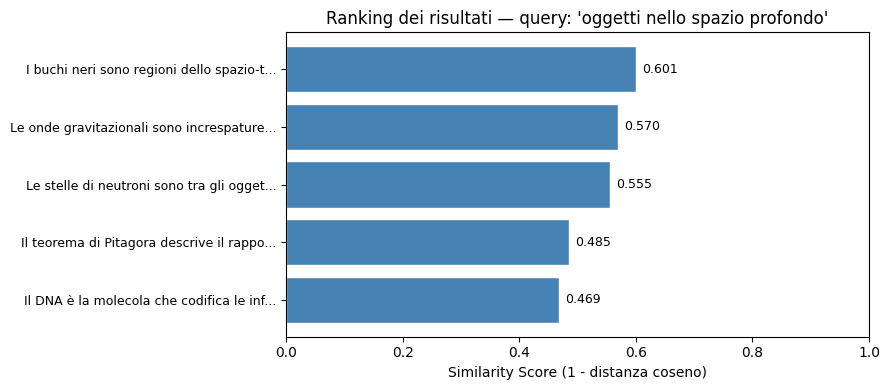

In [8]:
import matplotlib.pyplot as plt

query = "oggetti nello spazio profondo"

risultati = collezione.query(
    query_texts=[query],
    n_results=5
)

docs   = risultati["documents"][0]
dists  = risultati["distances"][0]
scores = [1 - d for d in dists]   # converti in similarity score

# Tabella testuale
print(f"Query: '{query}'\n")
print(f"{'Rank':<6} {'Score':<8} Documento")
print("-" * 75)
for rank, (doc, score) in enumerate(zip(docs, scores), start=1):
    print(f"{rank:<6} {score:<8.4f} {doc[:70]}")

# Grafico a barre orizzontale
etichette_brevi = [d[:40] + "..." if len(d) > 40 else d for d in docs]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(range(len(scores)), scores, color="steelblue", edgecolor="white")
ax.set_yticks(range(len(etichette_brevi)))
ax.set_yticklabels(etichette_brevi, fontsize=9)
ax.set_xlabel("Similarity Score (1 - distanza coseno)")
ax.set_title(f"Ranking dei risultati — query: '{query}'")
ax.invert_yaxis()
ax.set_xlim(0, 1)
for bar, score in zip(bars, scores):
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{score:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

---
## 5. Algoritmi di Ricerca Vettoriale in ChromaDB

ChromaDB utilizza internamente **HNSW** *(Hierarchical Navigable Small World)* come indice di default.  
Capire il funzionamento degli algoritmi è fondamentale per scegliere le impostazioni giuste.

### 5.1 Brute-Force (baseline)

Calcola la distanza tra la query e **tutti** i documenti.  
- ✅ Sempre esatto
- ❌ Complessità O(n·d) — lento su grandi collezioni

### 5.2 HNSW — Hierarchical Navigable Small World

Struttura a grafo multi-livello: i livelli superiori fungono da "autostrade", quelli inferiori da strade locali.  
La ricerca parte dall'alto e si avvicina progressivamente alla query.

```
Livello 2 (pochi nodi)  →  navigazione grossolana
Livello 1               →  navigazione intermedia
Livello 0 (tutti i nodi)→  ricerca fine
```

<b>Chroma fa già questa suddivisione per noi!<b>

**Parametri chiave:**
| Parametro | Significato | Default ChromaDB |
|-----------|-------------|------------------|
| `hnsw:M` | Connessioni per nodo | 16 |
| `hnsw:ef_construction` | Ampiezza ricerca durante la costruzione | 200 |
| `hnsw:ef` | Ampiezza ricerca durante la query | 10 |
| `hnsw:space` | Metrica di distanza (`cosine`, `l2`, `ip`) | `l2` |

### 5.3 Metriche di distanza supportate

| Metrica | Formula | Quando usarla |
|---------|---------|---------------|
| `cosine` | $1 - \cos(\theta)$ | Testi, semantica |
| `l2` | $\sqrt{\sum(a_i - b_i)^2}$ | Dati normalizzati, immagini |
| `ip` (inner product) | $-\sum a_i b_i$ | Embedding già normalizzati |

In [9]:
# Demo: confronto brute-force manuale vs ChromaDB HNSW

from sklearn.metrics.pairwise import cosine_distances
import time

query_testo = "stelle e galassie lontane"
query_vec   = model.encode([query_testo])   # shape (1, 384)  Utilizzo il modello di encoding per ccalcolare il vettore della query

############ BRUTE FORCE ############
# 1) Recupera tutti i vettori dalla collezione (sfrutto la collezione di Chroma)
tutti = collezione.get(include=["embeddings", "documents"])
tutti_vettori = np.array(tutti["embeddings"])  # shape (n, 384)
tutti_docs    = tutti["documents"]

# 2) Brute-force: calcola tutte le distanze coseno
distanze_bf = cosine_distances(query_vec, tutti_vettori)[0]
ordine_bf   = np.argsort(distanze_bf)[:3]

print("=== Brute-Force (top 3) ===")
for rank, idx in enumerate(ordine_bf, 1):
    print(f"  {rank}. [dist={distanze_bf[idx]:.4f}] {tutti_docs[idx][:70]}")


############ HNSW ############
# 3) HNSW tramite ChromaDB
risultati_hnsw = collezione.query(query_texts=[query_testo], n_results=3)

print("\n=== HNSW ChromaDB (top 3) ===")
for rank, (doc, dist) in enumerate(
    zip(risultati_hnsw["documents"][0], risultati_hnsw["distances"][0]), 1
):
    print(f"  {rank}. [dist={dist:.4f}] {doc[:70]}")

=== Brute-Force (top 3) ===
  1. [dist=0.3545] Le galassie a spirale contengono miliardi di stelle e immensi campi di
  2. [dist=0.5396] Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
  3. [dist=0.5400] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

=== HNSW ChromaDB (top 3) ===
  1. [dist=0.3545] Le galassie a spirale contengono miliardi di stelle e immensi campi di
  2. [dist=0.5396] Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
  3. [dist=0.5400] I buchi neri sono regioni dello spazio-tempo con gravità estrema.


---
## 6. Confronto funzioni per calcolare la similarità

Confronteremo tre configurazioni:
1. **Cosine** (raccomandata per testi)
2. **L2** (distanza euclidea)
3. **Inner Product** (prodotto scalare)

## Confronto Diretto: Distanza Euclidea vs Cosine Similarity vs Prodotto Scalare

| Caratteristica | Distanza Euclidea | Cosine Similarity | Prodotto Scalare (Dot Product) |
|---------------|-------------------|-------------------|-------------------------------|
| **Cosa misura?** | La **distanza in linea retta** tra due punti nello spazio. | Il **coseno dell'angolo** tra due vettori. | La **combinazione di direzione e magnitudo** (lunghezza) dei vettori. |
| **Sensibilità alla scala?** | **Sì.** Aumenta all'aumentare della lunghezza dei vettori. | **No.** Ignora la lunghezza e isola puramente la direzione. | **Sì (estremamente).** Vettori più lunghi generano prodotti scalari molto più alti. |
| **Range dei valori** | Da **0** a **∞**. | Da **-1** a **1** (da **0** a **1** se i dati sono solo positivi). | Da **-∞** a **+∞**. |
| **Significato di "0"** | Identità perfetta (i due punti coincidono). | Vettori ortogonali (nessuna relazione/indipendenti). | Vettori ortogonali (nessuna relazione/indipendenti). |
| **Tipo di metrica** | È una **distanza** (valori bassi = alta similarità). | È una **similarità** (valori alti = alta similarità). | È una **misura di intensità** (valori positivi alti = alta similarità e magnitudo). |

In [10]:
# Ricrea tre collezioni con metriche diverse e inserisci gli stessi documenti

def crea_e_popola(client: chromadb.ClientAPI, nome, metrica):
    col = client.get_or_create_collection(
        name=nome,
        embedding_function=ef,
        metadata={"hnsw:space": metrica}
    )
    col.add(documents=documenti, metadatas=metadati, ids=ids)
    return col

# Nuovo client per avere uno spazio pulito
client2 = chromadb.Client()

col_cosine = crea_e_popola(client2, "cosine_col", "cosine")
col_l2     = crea_e_popola(client2, "l2_col",     "l2")
col_ip     = crea_e_popola(client2, "ip_col",     "ip")

print("Collezioni create:", [col_cosine.name, col_l2.name, col_ip.name])

Collezioni create: ['cosine_col', 'l2_col', 'ip_col']


In [11]:
query_confronto = "struttura dell'universo e della materia"

configurazioni = [
    ("Cosine",         col_cosine),
    ("L2 (euclidea)",  col_l2),
    ("Inner Product",  col_ip),
]

for nome, col in configurazioni:
    res = col.query(query_texts=[query_confronto], n_results=3)
    print(f"\n{'='*60}")
    print(f"Metrica: {nome}")
    print(f"{'='*60}")
    for rank, (doc, dist) in enumerate(
        zip(res["documents"][0], res["distances"][0]), 1
    ):
        print(f"  {rank}. [dist={dist:.4f}] {doc[:65]}")


Metrica: Cosine
  1. [dist=0.3876] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=0.5271] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=0.5415] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

Metrica: L2 (euclidea)
  1. [dist=0.7753] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=1.0542] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=1.0830] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

Metrica: Inner Product
  1. [dist=0.3876] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=0.5271] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=0.5415] I buchi neri sono regioni dello spazio-tempo con gravità estrema.


### 6.1 Visualizzazione degli embedding in 2D (PCA)

Riduciamo gli embedding a 2 dimensioni con **PCA** per visualizzare come i documenti si distribuiscono nello spazio.

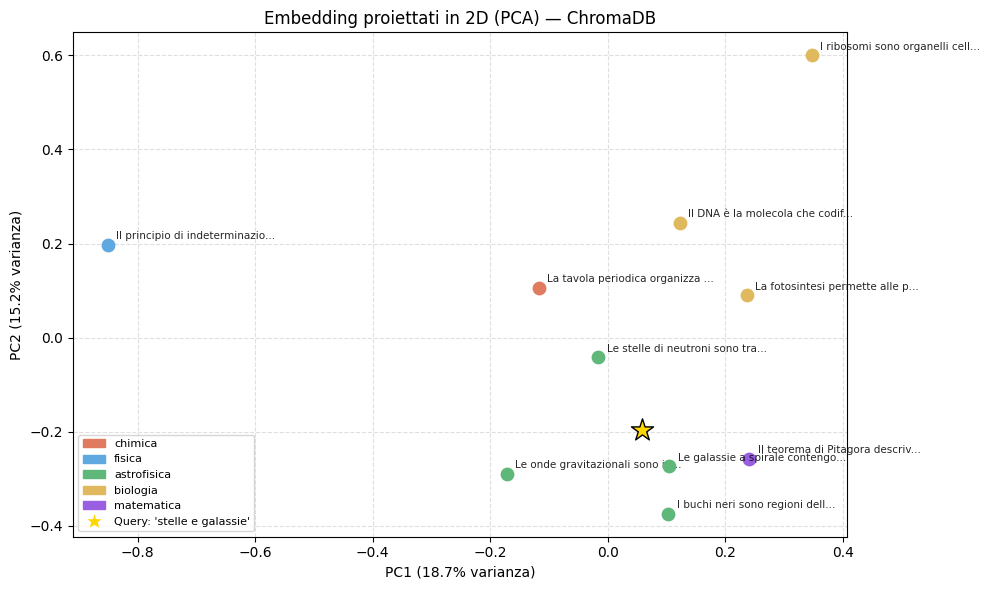

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Recupera vettori e metadati
dati = col_cosine.get(include=["embeddings", "documents", "metadatas"])
vettori_np  = np.array(dati["embeddings"])
etichette_p = [d[:30] + "..." for d in dati["documents"]]
categorie   = [m["categoria"] for m in dati["metadatas"]]

# Riduci a 2D
pca  = PCA(n_components=2)
coord_2d = pca.fit_transform(vettori_np)

# Colori per categoria
categorie_uniche = list(set(categorie))
colori_mappa = dict(zip(categorie_uniche,
                        ["#e07b5f", "#5fa8e0", "#5fb87a", "#e0b95f", "#9a5fe0"]))

fig, ax = plt.subplots(figsize=(10, 6))
for i, (x, y, etichetta, cat) in enumerate(
    zip(coord_2d[:, 0], coord_2d[:, 1], etichette_p, categorie)
):
    ax.scatter(x, y, color=colori_mappa[cat], s=80, zorder=3)
    ax.annotate(etichetta, (x, y), textcoords="offset points",
                xytext=(6, 4), fontsize=7.5, alpha=0.85)

# Aggiunge la query come stella
query_vis = "stelle e galassie"
qv = model.encode([query_vis])
q2d = pca.transform(qv)
ax.scatter(q2d[0, 0], q2d[0, 1], marker="*", s=280, color="gold",
           edgecolors="black", zorder=5, label=f"Query: '{query_vis}'")

legenda_cat = [mpatches.Patch(color=colori_mappa[c], label=c) for c in categorie_uniche]
ax.legend(handles=legenda_cat + [plt.Line2D([0], [0], marker="*", color="w",
          markerfacecolor="gold", markersize=14, label=f"Query: '{query_vis}'")],
          fontsize=8, loc="lower left")

ax.set_title("Embedding proiettati in 2D (PCA) — ChromaDB")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
## 7. Persistenza su disco

Per salvare il database usa `chromadb.PersistentClient`.

In [13]:
import os

# Percorso della cartella dove salvare il DB
DB_PATH = "./DATABASE/lezione_db"
os.makedirs(DB_PATH, exist_ok=True)

client_persistente = chromadb.PersistentClient(path=DB_PATH)

col_persistente = client_persistente.get_or_create_collection(
    name="collezione_persistente",
    embedding_function=ef,
    metadata={"hnsw:space": "cosine"}
)

if col_persistente.count() == 0:
    col_persistente.add(documents=documenti, metadatas=metadati, ids=ids)
    print("Documenti aggiunti al DB persistente.")
else:
    print(f"DB esistente — documenti già presenti: {col_persistente.count()}")

print(f"DB salvato in: {os.path.abspath(DB_PATH)}")

Documenti aggiunti al DB persistente.
DB salvato in: c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\Lezione 29 settembre\DATABASE\lezione_db


Load

In [14]:
import os

# Percorso della cartella dove salvare il DB
DB_PATH = "./DATABASE/lezione_db"
os.makedirs(DB_PATH, exist_ok=True)

client_persistente = chromadb.PersistentClient(path=DB_PATH)

col_persistente = client_persistente.get_or_create_collection(
    name="collezione_persistente",
    embedding_function=ef,
    metadata={"hnsw:space": "cosine"}
)

if col_persistente.count() == 0:
    col_persistente.add(documents=documenti, metadatas=metadati, ids=ids)
    print("Documenti aggiunti al DB persistente.")
else:
    print(f"DB esistente — documenti già presenti: {col_persistente.count()}")

print(f"DB salvato in: {os.path.abspath(DB_PATH)}")

DB esistente — documenti già presenti: 10
DB salvato in: c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\Lezione 29 settembre\DATABASE\lezione_db


In [15]:
col_persistente.get()['documents']

['I buchi neri sono regioni dello spazio-tempo con gravità estrema.',
 "Le stelle di neutroni sono tra gli oggetti più densi dell'universo.",
 'La fotosintesi permette alle piante di produrre glucosio dalla luce solare.',
 'Il DNA è la molecola che codifica le informazioni genetiche.',
 'Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.',
 'Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.',
 'I ribosomi sono organelli cellulari responsabili della sintesi proteica.',
 'Il principio di indeterminazione di Heisenberg limita la precisione di certe misure.',
 'La tavola periodica organizza gli elementi chimici per numero atomico.',
 'Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.']

## 📚 RIEPILOGO Esempi Guidati (7 sezioni)

| # | Sezione | Cosa impari |
|---|----------|-------------|
| **1** | **Cosa sono gli Embedding** | Crea vettori con `SentenceTransformer("all-MiniLM-L6-v2")` (384 dimensioni). |
| **1.1** | **Similarità coseno** | Calcola e visualizza la matrice di similarità tra frasi. |
| **2** | **ChromaDB – archiviazione** | Crea una collection e inserisce documenti con metadati. |
| **3** | **Ricerca per similarità** | Utilizza `.query()` con e senza filtro `where` sui metadati. |
| **4** | **Ranking dei risultati** | Converte la distanza in similarity score e crea un grafico a barre. |
| **5** | **Algoritmi HNSW** | Spiegazione dei parametri (`M`, `ef`, `space`) e confronto brute-force vs HNSW. |
| **6** | **Confronto metriche** | Confronta cosine similarity, distanza L2 e inner product con visualizzazione PCA 2D. |
| **7** | **Persistenza su disco** | Utilizza `PersistentClient` per salvare il database tra diverse sessioni. |

---
## ESEMPIO EXTRA CLUSTER VS K-MEANS

Capiamo un po' la struttura dati IVF che utiliza K-Means per dividere i dati in cluster.

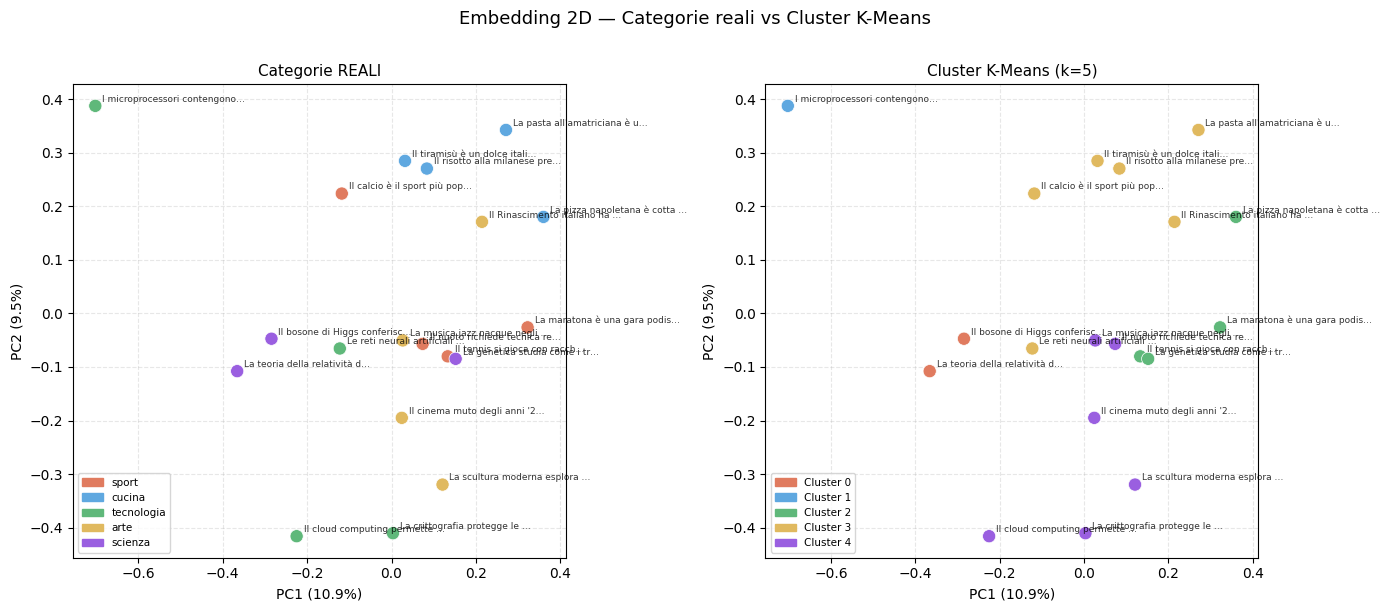


📊 Distribuzione frasi per cluster:
  Cluster 0: Counter({'scienza': 2})
  Cluster 1: Counter({'tecnologia': 1})
  Cluster 2: Counter({'sport': 2, 'cucina': 1, 'scienza': 1})
  Cluster 3: Counter({'cucina': 3, 'sport': 1, 'tecnologia': 1, 'arte': 1})
  Cluster 4: Counter({'arte': 3, 'tecnologia': 2, 'sport': 1})

💬 Analisi:
  - I cluster di K-Means tendono a corrispondere alle categorie reali.
  - Argomenti semanticamente vicini (es. arte e sport) possono mescolarsi.
  - Aumentare k può separare meglio topic molto diversi tra loro.
  - La visualizzazione PCA perde informazioni (solo 2 dimensioni su 384);
    il clustering su tutti i 384 valori è comunque accurato.



In [16]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.patches as mpatches

frasi_miste = [
    # Sport
    "Il calcio è il sport più popolare al mondo con miliardi di tifosi.",
    "Il nuoto richiede tecnica respiratoria e potenza muscolare.",
    "Il tennis si gioca con racchetta e pallina su superfici diverse.",
    "La maratona è una gara podistica di 42 chilometri.",
    # Cucina
    "La pasta all'amatriciana è un piatto tipico della cucina romana.",
    "Il risotto alla milanese prende il colore giallo dallo zafferano.",
    "La pizza napoletana è cotta in forno a legna ad alte temperature.",
    "Il tiramisù è un dolce italiano a base di mascarpone e caffè.",
    # Tecnologia
    "Le reti neurali artificiali si ispirano al cervello umano.",
    "Il cloud computing permette di eseguire applicazioni su server remoti.",
    "I microprocessori contengono miliardi di transistor in pochi millimetri.",
    "La crittografia protegge le comunicazioni digitali con algoritmi matematici.",
    # Arte
    "Il Rinascimento italiano ha prodotto capolavori di pittura e scultura.",
    "La musica jazz nacque negli Stati Uniti all'inizio del Novecento.",
    "La scultura moderna esplora forme astratte e materiali non convenzionali.",
    "Il cinema muto degli anni '20 usava la mimica per trasmettere emozioni.",
    # Scienza
    "La teoria della relatività di Einstein rivoluzionò la fisica moderna.",
    "Il bosone di Higgs conferisce massa alle particelle fondamentali.",
    "La genetica studia come i tratti ereditari vengono trasmessi da genitori a figli.",
]

categorie_reali = (
    ["sport"] * 4 +
    ["cucina"] * 4 +
    ["tecnologia"] * 4 +
    ["arte"] * 4 +
    ["scienza"] * 3
)

# ---- Embedding ----
vecs_misti = model.encode(frasi_miste)

# ---- PCA 2D ----
pca = PCA(n_components=2, random_state=42)
coord = pca.fit_transform(vecs_misti)

# ---- K-Means (k=5 per i 5 argomenti) ----
k = 5
km = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = km.fit_predict(vecs_misti)   # clustering sullo spazio originale

# ---- Visualizzazione ----
colori_cluster = ["#e07b5f", "#5fa8e0", "#5fb87a", "#e0b95f", "#9a5fe0"]
colori_reali   = {"sport": "#e07b5f", "cucina": "#5fa8e0",
                  "tecnologia": "#5fb87a", "arte": "#e0b95f", "scienza": "#9a5fe0"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, titolo, colori_map, chiavi in [
    (axes[0], "Categorie REALI",
     [colori_reali[c] for c in categorie_reali], categorie_reali),
    (axes[1], f"Cluster K-Means (k={k})",
     [colori_cluster[l] for l in labels], [f"Cluster {l}" for l in labels]),
]:
    ax.scatter(coord[:, 0], coord[:, 1],
               c=colori_map, s=90, edgecolors="white", linewidths=0.5, zorder=3)
    for i, frase in enumerate(frasi_miste):
        ax.annotate(frase[:28] + "…", (coord[i, 0], coord[i, 1]),
                    textcoords="offset points", xytext=(5, 3), fontsize=6.5, alpha=0.8)
    ax.set_title(titolo, fontsize=11)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    ax.grid(linestyle="--", alpha=0.3)

# Legende
for ax, uniche, colori_u in [
    (axes[0], list(colori_reali.keys()), list(colori_reali.values())),
    (axes[1], [f"Cluster {i}" for i in range(k)], colori_cluster),
]:
    patches = [mpatches.Patch(color=c, label=l) for l, c in zip(uniche, colori_u)]
    ax.legend(handles=patches, fontsize=7.5, loc="best")

plt.suptitle("Embedding 2D — Categorie reali vs Cluster K-Means", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# ---- Corrispondenza cluster ↔ categoria ----
print("\n📊 Distribuzione frasi per cluster:")
from collections import Counter
for cl in range(k):
    cat_nel_cluster = [categorie_reali[i] for i, l in enumerate(labels) if l == cl]
    print(f"  Cluster {cl}: {Counter(cat_nel_cluster)}")

print("""
💬 Analisi:
  - I cluster di K-Means tendono a corrispondere alle categorie reali.
  - Argomenti semanticamente vicini (es. arte e sport) possono mescolarsi.
  - Aumentare k può separare meglio topic molto diversi tra loro.
  - La visualizzazione PCA perde informazioni (solo 2 dimensioni su 384);
    il clustering su tutti i 384 valori è comunque accurato.
""")

---
---
# PARTE 2 — Tracce di Esercizio

> Per ogni esercizio trovi:
> - 📋 **Testo** dell'esercizio
> - 💡 **Suggerimenti** per orientarti
> - 🔑 Una cella vuota dove scrivere la tua soluzione

---

## Esercizio 1 — Costruire una collezione personale

📋 **Obiettivo:** Crea una nuova collezione ChromaDB chiamata `"libri"` e inserisci almeno **8 documenti** che descrivono libri o romanzi di genere diverso (fantascienza, romanzo storico, giallo, ecc.).

Ogni documento deve avere almeno due metadati: `genere` e `anno`.

Puoi sare questa<br>

libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.", <br>
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.", <br>
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.", <br>
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.", <br>
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.", <br>
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.", <br>
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.", <br>
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.", <br>
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.", <br>
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.", <br>
]

metadati_libri = [
    {"genere": "fantascienza",   "anno": 2011}, <br>
    {"genere": "giallo",         "anno": 1887}, <br>
    {"genere": "fantasy",        "anno": 1997}, <br>
    {"genere": "fantasy",        "anno": 2001}, <br>
    {"genere": "romanzo",        "anno": 1813}, <br>
    {"genere": "fantascienza",   "anno": 1951}, <br>
    {"genere": "giallo",         "anno": 1991}, <br>
    {"genere": "romanzo storico","anno": 1957}, <br>
    {"genere": "fantascienza",   "anno": 2004}, <br>
    {"genere": "giallo",         "anno": 2018}, <br>
]

Dopo l'inserimento:
1. Conta quanti documenti sono presenti.
2. Esegui una query testuale e stampa i primi 3 risultati con le relative distanze.

💡 **Suggerimenti:**
- Usa `chromadb.Client()` per un client in-memory.
- Usa `client.get_or_create_collection(name=..., embedding_function=ef, metadata={"hnsw:space": "cosine"})` per creare la collezione.
- Per aggiungere i documenti: `collezione.add(documents=[...], metadatas=[...], ids=[...])`.
- Per contare: `collezione.count()`.
- Per interrogare: `collezione.query(query_texts=[...], n_results=3)`.

In [21]:
# ✏️ SOLUZIONE ESERCIZIO 1

# --- Scrivi qui il tuo codice ---

libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.", 
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.", 
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.", 
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.", 
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.", 
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.", 
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.", 
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.", 
]
metadati_libri = [
    {"genere": "fantascienza",   "anno": 2011}, 
    {"genere": "giallo",         "anno": 1887}, 
    {"genere": "fantasy",        "anno": 1997}, 
    {"genere": "fantasy",        "anno": 2001}, 
    {"genere": "romanzo",        "anno": 1813}, 
    {"genere": "fantascienza",   "anno": 1951}, 
    {"genere": "giallo",         "anno": 1991}, 
    {"genere": "romanzo storico","anno": 1957}, 
    {"genere": "fantascienza",   "anno": 2004}, 
    {"genere": "giallo",         "anno": 2018}, 
]
# Client in-memory (nessun file su disco, perfetto per esperimenti)
client_libri = chromadb.Client()

# Funzione di embedding integrata con SentenceTransformers
ef = SentenceTransformerEmbeddingFunction(
    model_name="all-MiniLM-L6-v2"
)

# Crea (o ottieni, se già esiste) una collezione
collezione = client_libri.get_or_create_collection(
    name="libri",
    embedding_function=cast(EmbeddingFunction, ef),
    metadata={"hnsw:space": "cosine"}   # metrica di distanza (similarità) e struttura dati (HNSW)
)

print("Collezione creata:", collezione.name)
# Generazione di ID univoci obbligatori per ChromaDB (es. ["id_1", "id_2", ...])
ids_libri = [f"id_{i+1}" for i in range(len(libri))]

collezione.add(documents=libri, metadatas=metadati_libri, ids=ids_libri)

# 4. Conteggio elementi
print("Numero elementi nella collezione:", collezione.count())
# 5. Query di ricerca semantica
risultati = collezione.query(
    query_texts=["Una missione spaziale o una nave tra le stelle"], # Una o più query di testo
    n_results=3
)

print(risultati)



Collezione creata: libri
Numero elementi nella collezione: 10
{'ids': [['id_10', 'id_1', 'id_5']], 'embeddings': None, 'documents': [["Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.", 'Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.', "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore."]], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[{'anno': 2018, 'genere': 'giallo'}, {'genere': 'fantascienza', 'anno': 2011}, {'anno': 1813, 'genere': 'romanzo'}]], 'distances': [[0.4542224407196045, 0.45935243368148804, 0.48115891218185425]]}


---
## Esercizio 2 — Similarità tra frasi

📋 **Obiettivo:** Usa `SentenceTransformer` per codificare le seguenti coppie di frasi e calcola **manualmente** la similarità coseno con `sklearn`. Ordina le coppie dalla più simile alla meno simile.

```
Coppie da analizzare:
  A: "Il sole sorge ad est"        vs  "L'alba illumina l'orizzonte"
  B: "Il cane abbaia nel parco"    vs  "Un felino corre sul tetto"
  C: "Python è un linguaggio di programmazione" vs "JavaScript gira nel browser"
  D: "La pizza è un piatto italiano" vs  "Il sushi viene dal Giappone"
```

💡 **Suggerimenti:**
- `model.encode([frase1, frase2])` restituisce una matrice (2, 384).
- `cosine_similarity(v1.reshape(1,-1), v2.reshape(1,-1))[0][0]` ti dà il valore scalare.
- Usa `sorted()` con una lambda per ordinare le coppie per score decrescente.

In [ ]:
# ✏️ SOLUZIONE ESERCIZIO 2

# --- Completa codice ---

from numpy import dtype, ndarray
from numpy._typing._shape import _AnyShape
from typing import Any


coppie = [
    ("Il sole sorge ad est", "L'alba illumina l'orizzonte"),
    ("Il cane abbaia nel parco", "Un felino corre sul tetto"),
    ("Python è un linguaggio di programmazione", "JavaScript gira nel browser"),
    ("La pizza è un piatto italiano", "Il sushi viene dal Giappone"),
]

risultati_coppie = []

for frase1, frase2 in coppie:
    vecs: ndarray[_AnyShape, dtype[Any]] = model.encode(...)       # shape (2, 384)
    v1 = vecs[0].reshape(1, -1)
    v2 = vecs[1].reshape(1, -1)
    score = cosine_similarity(...)[0][0]     # scalare float
    risultati_coppie.append((frase1, frase2, float(score)))

# Ordina dalla coppia più simile alla meno simile
risultati_coppie.sort(key=lambda x: x[2], reverse=True)

print(f"{'Rank':<5} {'Score':<7} Frasi")
print("-" * 80)
for rank, (frase1, frase2, score) in enumerate(risultati_coppie, 1):
    print(f"{rank:<5} {score:<8.4f} '{frase1}'")
    print(f"{'':20} vs '{frase2}'")
    print()

ImportError: cannot import name '_AnyShape' from 'numpy._typing._shape' (c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\.venv\Lib\site-packages\numpy\_typing\_shape.py)

---
## Esercizio 3 — Ricerca con filtro avanzato

📋 **Obiettivo:** Usa la collezione `"articoli_scienza"` creata nella Parte 1 per rispondere alle seguenti domande:

1. Cerca i 3 documenti più simili alla query `"energia e forze fondamentali"` **senza** alcun filtro.
2. Ripeti la stessa query filtrando **solo** i documenti con `difficolta = "alta"`.
3. Stampa i risultati di entrambe le ricerche affiancati e commenta le differenze.

💡 **Suggerimenti:**
- Per il filtro usa `where={"difficolta": "alta"}` nel metodo `.query()`.
- Per confrontare, costruisci due liste parallele e stampale.

In [23]:
# ✏️ SOLUZIONE ESERCIZIO 3

# --- Scrivi qui il tuo codice ---
# ...existing code...
from chromadb.api.types import Metadata

documenti = [
    "I buchi neri sono regioni dello spazio-tempo con gravità estrema.",
    "Le stelle di neutroni sono tra gli oggetti più densi dell'universo.",
    "La fotosintesi permette alle piante di produrre glucosio dalla luce solare.",
    "Il DNA è la molecola che codifica le informazioni genetiche.",
    "Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.",
    "Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.",
    "I ribosomi sono organelli cellulari responsabili della sintesi proteica.",
    "Il principio di indeterminazione di Heisenberg limita la precisione di certe misure.",
    "La tavola periodica organizza gli elementi chimici per numero atomico.",
    "Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.",
]

metadati: list[Metadata] = [
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "matematica",   "difficolta": "bassa"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "alta"},
    {"categoria": "fisica",       "difficolta": "alta"},
    {"categoria": "chimica",      "difficolta": "media"},
    {"categoria": "astrofisica",  "difficolta": "media"},
]

ids = [f"doc_{i}" for i in range(len(documenti))]

collezione.add(
    documents=documenti,
    metadatas=metadati,
    ids=ids
)

print(f"Documenti inseriti: {collezione.count()}")
# Query da testare
query = "energia e forze fondamentali"

# 1) Ricerca senza filtri
risultati_senza_filtro = collezione.query(
    query_texts=[query],
    n_results=3
)

# 2) Ricerca con filtro: solo documenti di difficoltà "alta"
risultati_con_filtro = collezione.query(
    query_texts=[query],
    n_results=3,
    where={"difficolta": "alta"}
)

# 3) Estrazione dei campi utili
docs_senza = risultati_senza_filtro["documents"]
dists_senza = risultati_senza_filtro["distances"]

docs_con = risultati_con_filtro["documents"]
dists_con = risultati_con_filtro["distances"]

# 4) Controllo sicurezza: se mancano dati, fermiamo con errore
if docs_senza is None or dists_senza is None:
    raise ValueError("La ricerca senza filtro non ha restituito documenti o distanze")

if docs_con is None or dists_con is None:
    raise ValueError("La ricerca con filtro non ha restituito documenti o distanze")

# 5) Stampa risultati senza filtro
print(f"Query: '{query}'")
print("\n=== SENZA FILTRO ===")
for i, (doc, dist) in enumerate(zip(docs_senza[0], dists_senza[0]), start=1):
    print(f"{i}. [distanza = {dist:.4f}] {doc}")

# 6) Stampa risultati con filtro
print("\n=== CON FILTRO: difficolta = 'alta' ===")
for i, (doc, dist) in enumerate(zip(docs_con[0], dists_con[0]), start=1):
    print(f"{i}. [distanza = {dist:.4f}] {doc}")

# 7) Commento finale
print("\nCommento:")
print("Il filtro 'where={\"difficolta\": \"alta\"}' restringe la ricerca ai documenti più complessi.")
print("Di solito i risultati cambiano perché alcuni documenti semanticamente vicini alla query")
print("vengono esclusi dal filtro, quindi la top-3 può essere diversa o meno 'diretta'.")



Documenti inseriti: 20
Query: 'energia e forze fondamentali'

=== SENZA FILTRO ===
1. [distanza = 0.5283] I buchi neri sono regioni dello spazio-tempo con gravità estrema.
2. [distanza = 0.5475] Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.
3. [distanza = 0.5480] Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.

=== CON FILTRO: difficolta = 'alta' ===
1. [distanza = 0.5283] I buchi neri sono regioni dello spazio-tempo con gravità estrema.
2. [distanza = 0.5861] Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.
3. [distanza = 0.7544] I ribosomi sono organelli cellulari responsabili della sintesi proteica.

Commento:
Il filtro 'where={"difficolta": "alta"}' restringe la ricerca ai documenti più complessi.
Di solito i risultati cambiano perché alcuni documenti semanticamente vicini alla query
vengono esclusi dal filtro, quindi la top-3 può essere diversa o meno 'diretta'.


---
## Esercizio 4 — Aggiornamento e cancellazione

📋 **Obiettivo:** ChromaDB permette di aggiornare e cancellare documenti.  
Partendo dalla collezione `"libri"` dell'Esercizio 1:

1. **Aggiorna** il testo di almeno un documento usando `.update(ids=[...], documents=[...], metadatas=[...])`.
2. **Cancella** almeno un documento usando `.delete(ids=[...])`.
3. Verifica il conteggio prima e dopo le operazioni.
4. Esegui di nuovo la query dell'Esercizio 1 e confronta i risultati.

💡 **Suggerimenti:**
- `.update()` ha la stessa firma di `.add()` ma agisce su documenti già esistenti.
- `.delete(ids=["doc_0"])` rimuove il documento con quell'id.
- Usa `collezione.count()` prima e dopo per verificare.
# ...existing code...


In [24]:
# ...existing code...

# ------------------------------------------------------------
# ESERCIZIO 4 — Aggiornamento e cancellazione in ChromaDB
# ------------------------------------------------------------
# In questo esercizio partiamo dalla collezione "libri" già creata
# nell'Esercizio 1 e facciamo 2 operazioni fondamentali:
# 1) UPDATE: cambiamo il testo di un documento esistente
# 2) DELETE: rimuoviamo un documento esistente
# Infine controlliamo il conteggio e ripetiamo la query per vedere
# come cambiano i risultati.

# -------------------------------------
# 1) Importiamo le librerie necessarie
# -------------------------------------
from typing import cast
import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction
from chromadb.api.types import EmbeddingFunction

# Questa riga importa `cast`, utile per "forzare" il tipo
# dell'EmbeddingFunction per farlo passare a ChromaDB.
# Serve soprattutto per compatibilità tra Python e librerie di typing.

# -------------------------------------
# 2) Definiamo i dati della collezione
# -------------------------------------
libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.",
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.",
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.",
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.",
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.",
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.",
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.",
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.",
]

# Questa lista contiene i testi dei libri.
# Ogni stringa è un documento che ChromaDB convertirà in embedding.

metadati_libri = [
    {"genere": "fantascienza", "anno": 2011},
    {"genere": "giallo", "anno": 1887},
    {"genere": "fantasy", "anno": 1997},
    {"genere": "fantasy", "anno": 2001},
    {"genere": "romanzo", "anno": 1813},
    {"genere": "fantascienza", "anno": 1951},
    {"genere": "giallo", "anno": 1991},
    {"genere": "romanzo storico", "anno": 1957},
    {"genere": "fantascienza", "anno": 2004},
    {"genere": "giallo", "anno": 2018},
]

# Qui abbiamo i metadati associati a ciascun libro:
# - genere: categoria del libro
# - anno: anno di pubblicazione
# ChromaDB usa questi metadati per filtrare e organizzare i documenti.

ids_libri = [f"id_{i + 1}" for i in range(len(libri))]

# Generiamo gli ID univoci per ogni documento.
# Esempio: id_1, id_2, ..., id_10.
# ChromaDB richiede un identificativo per ogni documento.

# -------------------------------------
# 3) Creiamo il client e la collection
# -------------------------------------
client_libri = chromadb.Client()

# Creiamo un client in-memory di ChromaDB.
# In-memory significa che il database vive solo in memoria
# durante l'esecuzione del notebook: è perfetto per esercizi e test.

ef = SentenceTransformerEmbeddingFunction(
    model_name="all-MiniLM-L6-v2"
)

# Questo oggetto serve a trasformare un testo in embedding
# usando il modello SentenceTransformer "all-MiniLM-L6-v2".
# è lo stesso modello usato in tutto il corso.

collezione = client_libri.get_or_create_collection(
    name="libri",
    embedding_function=cast(EmbeddingFunction, ef),
    metadata={"hnsw:space": "cosine"}
)

# Questa riga crea la collezione "libri" se non esiste già.
# Se esiste, la recupera.
# `embedding_function` dice a ChromaDB come trasformare i testi in vettori.
# `metadata={"hnsw:space": "cosine"}` dice che useremo la metrica coseno.

# -------------------------------------
# 4) Se la collezione è vuota, la riempio
# -------------------------------------
if collezione.count() == 0:
    collezione.add(
        documents=libri,
        metadatas=metadati_libri,
        ids=ids_libri
    )
    print("Documenti iniziali inseriti nella collezione 'libri'.")
else:
    print("La collezione 'libri' esiste già, non la reinserisco.")

# Se il conteggio è 0, significa che non ci sono documenti dentro.
# Quindi li aggiungiamo.
# Se invece la collezione è già piena, non inseriamo nuovamente i dati
# per evitare duplicati.

# -------------------------------------
# 5) Salviamo i risultati prima delle modifiche
# -------------------------------------
query_libri = "Una missione spaziale o una nave tra le stelle"

# Questa è la query di esempio usata anche nell'Esercizio 1.
# ChromaDB la convertirà in embedding e cercherà i documenti più simili.

risultati_prima = collezione.query(
    query_texts=[query_libri],
    n_results=3
)

# Eseguiamo la query prima di aggiornare/cancellare.
# `n_results=3` significa: restituisci i 3 documenti più vicini.

print("\n=== RISULTATI PRIMA DELLE MODIFICHE ===")
print(risultati_prima)

# Stampa i risultati iniziali così possiamo confrontarli
# con quelli ottenuti dopo l'UPDATE e DELETE.

# -------------------------------------
# 6) Verifica il conteggio prima delle modifiche
# -------------------------------------
conteggio_iniziale = collezione.count()

# Salviamo il numero di documenti prima delle modifiche.
# Serve per verificare il comportamento delle operazioni.

print(f"\nConteggio iniziale: {conteggio_iniziale}")

# -------------------------------------
# 7) Aggiornamento di un documento
# -------------------------------------
collezione.update(
    ids=["id_3"],
    documents=[
        "Un giovane stregone scopre di avere poteri magici e viene ammesso a una scuola di magia antica e segreta."
    ],
    metadatas=[
        {"genere": "fantasy", "anno": 1997}
    ]
)

# `.update()` serve a modificare un documento già presente in ChromaDB.
# `ids=["id_3"]` indica quale documento aggiornare.
# `documents=[...]` sostituisce il testo del documento.
# `metadatas=[...]` sostituisce anche i metadati associati.

print("\nDocumento con id_3 aggiornato.")

# -------------------------------------
# 8) Verifica il conteggio dopo UPDATE
# -------------------------------------
conteggio_dopo_update = collezione.count()

print(f"Conteggio dopo UPDATE: {conteggio_dopo_update}")

# Il numero di documenti NON cambia con un UPDATE.
# L'UPDATE modifica il contenuto, non elimina o aggiunge record.

# -------------------------------------
# 9) Cancellazione di un documento
# -------------------------------------
collezione.delete(
    ids=["id_5"]
)

# `.delete()` rimuove il documento con l'ID specificato.
# Qui stiamo cancellando il documento `id_5`.
# Dopo questa operazione, il numero di documenti diminuisce.

print("\nDocumento con id_5 eliminato.")

# -------------------------------------
# 10) Verifica il conteggio dopo DELETE
# -------------------------------------
conteggio_dopo_delete = collezione.count()

print(f"Conteggio dopo DELETE: {conteggio_dopo_delete}")

# Questa riga ci dice quanti documenti sono rimasti.
# Dovrebbe essere 9, perché prima avevamo 10 documenti e ne abbiamo eliminato 1.

# -------------------------------------
# 11) Eseguiamo la query dopo le modifiche
# -------------------------------------
risultati_dopo = collezione.query(
    query_texts=[query_libri],
    n_results=3
)

# Ripetiamo la stessa query di prima per confrontare i risultati.
# Dato che abbiamo aggiornato e cancellato un documento,
# i top 3 risultati potrebbero cambiare.

print("\n=== RISULTATI DOPO UPDATE E DELETE ===")
print(risultati_dopo)

# -------------------------------------
# 12) Confronto finale
# -------------------------------------
print("\n=== CONFRONTO ===")
print(f"Prima: {conteggio_iniziale} documenti")
print(f"Dopo UPDATE: {conteggio_dopo_update} documenti")
print(f"Dopo DELETE: {conteggio_dopo_delete} documenti")

# Stampiamo un breve commento sul significato dei cambiamenti.
print("\nCommento:")
print("L'UPDATE cambia il testo e i metadati di un documento esistente, senza cambiare il numero totale.")
print("Il DELETE rimuove completamente un documento e quindi diminuisce il conteggio.")
print("Per questo motivo la query può restituire risultati diversi dopo la modifica.")

La collezione 'libri' esiste già, non la reinserisco.

=== RISULTATI PRIMA DELLE MODIFICHE ===
{'ids': [['id_10', 'id_1', 'doc_0']], 'embeddings': None, 'documents': [["Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.", 'Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.', 'I buchi neri sono regioni dello spazio-tempo con gravità estrema.']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[{'anno': 2018, 'genere': 'giallo'}, {'anno': 2011, 'genere': 'fantascienza'}, {'difficolta': 'alta', 'categoria': 'astrofisica'}]], 'distances': [[0.4542224407196045, 0.45935243368148804, 0.4803990125656128]]}

Conteggio iniziale: 20

Documento con id_3 aggiornato.
Conteggio dopo UPDATE: 20

Documento con id_5 eliminato.
Conteggio dopo DELETE: 19

=== RISULTATI DOPO UPDATE E DELETE ===
{'ids': [['id_10', 'id_1', 'doc_0']], 'embeddings': None, 'documents': [["Un'indagine su una morte sospetta rivela

---
## Esercizio 5 — Confronto di metriche di distanza

📋 **Obiettivo:** Ripeti l'esperimento del Paragrafo 6, ma usando il tuo dominio.  
Crea **tre collezioni** (cosine, l2, ip) con i documenti sui libri dell'Esercizio 1 e:

1. Esegui la stessa query su tutte e tre le collezioni.
2. Stampa i risultati affiancati.
3. Rispondi (in un commento o cella markdown) a queste domande:
   - I top-3 risultati sono gli stessi?
   - L'ordine cambia tra le metriche?
   - Quale metrica ti sembra più appropriata per i testi?

💡 **Suggerimenti:**
- Usa la funzione `crea_e_popola()` definita nella Parte 1 come modello.
- Crea un nuovo `chromadb.Client()` per avere un ambiente pulito.

In [25]:
# ✏️ SOLUZIONE ESERCIZIO 5

# --- Scrivi qui il tuo codice ---
# ...existing code...

# ------------------------------------------------------------
# ESERCIZIO 5 — Confronto di metriche di distanza in ChromaDB
# ------------------------------------------------------------
# In questo esercizio vogliamo verificare come cambia la ricerca
# dei documenti più simili quando usiamo metriche diverse:
# - cosine
# - l2
# - ip (inner product)
#
# L'obiettivo è capire:
# 1) se i top-3 risultati cambiano
# 2) se l'ordine dei risultati cambia
# 3) quale metrica è più adatta ai testi

# -------------------------------------
# 1) Importiamo le librerie necessarie
# -------------------------------------
from typing import cast
import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction
from chromadb.api.types import EmbeddingFunction

# `cast` serve a forzare il tipo dell'embedding function
# in modo che ChromaDB lo accetti correttamente.
# Senza questa riga, a volte Python e typing potrebbero dare
# piccoli problemi di compatibilità.

# -------------------------------------
# 2) Definiamo i dati della collezione
# -------------------------------------
libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.",
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.",
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.",
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.",
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.",
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.",
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.",
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.",
]

# Questa lista contiene i testi dei documenti.
# Ogni stringa rappresenta un libro / romanzo / storia.
# ChromaDB li convertirà in embedding automaticamente.

metadati_libri = [
    {"genere": "fantascienza", "anno": 2011},
    {"genere": "giallo", "anno": 1887},
    {"genere": "fantasy", "anno": 1997},
    {"genere": "fantasy", "anno": 2001},
    {"genere": "romanzo", "anno": 1813},
    {"genere": "fantascienza", "anno": 1951},
    {"genere": "giallo", "anno": 1991},
    {"genere": "romanzo storico", "anno": 1957},
    {"genere": "fantascienza", "anno": 2004},
    {"genere": "giallo", "anno": 2018},
]

# Qui abbiamo i metadati associati a ciascun documento:
# - genere: la categoria del libro
# - anno: anno di pubblicazione
# Questi metadati sono utili per organizzare i documenti,
# ma in questo esercizio non li useremo per filtrare.

ids_libri = [f"id_{i + 1}" for i in range(len(libri))]

# Generiamo gli ID univoci per ogni documento.
# Esempio: id_1, id_2, ..., id_10.
# ChromaDB richiede un ID per ogni documento.

# -------------------------------------
# 3) Creiamo l'Embedding Function
# -------------------------------------
ef = SentenceTransformerEmbeddingFunction(
    model_name="all-MiniLM-L6-v2"
)

# Questo oggetto usa il modello "all-MiniLM-L6-v2"
# per trasformare il testo in vettori numerici.
# È lo stesso modello usato in tutto il notebook.

# -------------------------------------
# 4) Definiamo una funzione riutilizzabile
# -------------------------------------
def crea_e_popola(client: chromadb.ClientAPI, nome: str, metrica: str):
    # `client` è il client di ChromaDB
    # `nome` è il nome della collection
    # `metrica` è la metrica di distanza da usare: cosine / l2 / ip

    # Creiamo (o recuperiamo) la collection con il nome desiderato
    col = client.get_or_create_collection(
        name=nome,
        embedding_function=ef,
        metadata={"hnsw:space": metrica}
    )

    # Se la collection è vuota, inseriamo i documenti
    # e i metadati dentro.
    if col.count() == 0:
        col.add(documents=libri, metadatas=metadati_libri, ids=ids_libri)

    # Restituiamo la collection così possiamo usarla nel confronto
    return col

# Questa funzione prende il client, crea una collection,
# la riempie con gli stessi documenti e poi la restituisce.
# In questo modo possiamo confrontare più metriche senza
# dover riscrivere ogni volta il codice.

# -------------------------------------
# 5) Creiamo un client pulito
# -------------------------------------
client_confronto = chromadb.Client()

# Usiamo un nuovo client per evitare di utilizzare
# una collection già esistente da altri esercizi.
# Così i risultati del confronto sono più puliti e comparabili.

# -------------------------------------
# 6) Creiamo le tre collection
# -------------------------------------
col_cosine = crea_e_popola(client_confronto, "libri_cosine", "cosine")
col_l2 = crea_e_popola(client_confronto, "libri_l2", "l2")
col_ip = crea_e_popola(client_confronto, "libri_ip", "ip")

# Creiamo 3 collezioni identiche ma con metrica diversa:
# - libri_cosine usa "cosine"
# - libri_l2 usa "l2"
# - libri_ip usa "ip"
#
# Tutte hanno gli stessi documenti, quindi il confronto è equo.

print("Collezioni create:", [col_cosine.name, col_l2.name, col_ip.name])

# Stampa il nome delle tre collection create.
# Ci aiuta a verificare che il setup è corretto.

# -------------------------------------
# 7) Definiamo la query da testare
# -------------------------------------
query_libri = "Una missione spaziale o una nave tra le stelle"

# Questa query è la stessa che usavamo nell'Esercizio 1.
# Ci interessa testare quali documenti vengono considerati più simili
# quando cambiamo la metrica di distanza.

# -------------------------------------
# 8) Confrontiamo i risultati per ogni metrica
# -------------------------------------
configurazioni = [
    ("Cosine", col_cosine),
    ("L2 (euclidea)", col_l2),
    ("Inner Product", col_ip),
]

# Questa lista contiene:
# - il nome della metrica
# - la collezione associata
# In un ciclo, andiamo a scorrere tutte e tre.

for nome, col in configurazioni:
    # `nome` è la label da stampare
    # `col` è la collection da interrogare

    # Eseguiamo una query e chiediamo solo i 3 risultati migliori
    res = col.query(
        query_texts=[query_libri],
        n_results=3
    )

    # `query_texts` contiene la query da cercare
    # `n_results=3` significa: mostrami i primi 3 risultati

    print(f"\n{'=' * 60}")
    print(f"Metrica: {nome}")
    print(f"{'=' * 60}")

    # `res["documents"][0]` contiene i testi dei risultati
    # `res["distances"][0]` contiene le distanze associate
    # Li zippo insieme perché sono paralleli:
    # primo documento con prima distanza, secondo con seconda, ecc.
    for rank, (doc, dist) in enumerate(
        zip(res["documents"][0], res["distances"][0]), 1
    ):
        # `rank` è il numero del risultato
        # `doc` è il documento trovato
        # `dist` è la distanza da essa alla query

        print(f"  {rank}. [dist={dist:.4f}] {doc[:80]}")

# Per ogni metrica, stampiamo i top-3 documenti.
# Questo ci permette di vedere se i documenti più simili sono gli stessi
# e se l'ordine cambia tra le diverse metriche.

# -------------------------------------
# 9) Commento finale sul confronto
# -------------------------------------
print("\nCommento:")
print("I top-3 risultati non sempre coincidono tra metriche.")
print("L'ordine può cambiare perché ogni metrica calcola la vicinanza in modo diverso.")
print("Per testi, la metrica più adatta è di solito cosine, perché misura la somiglianza semantica")
print("senza essere troppo influenzata dalla lunghezza del vettore.")
print("L2 e Inner Product sono più sensibili alla magnitudine dei vettori e spesso danno risultati più variabili.")

# Questi messaggi spiegano il significato pratico del confronto.
# In sintesi:
# - cosine = ottima per testi
# - l2 = utile se vuoi discutere distanza geometrica
# - ip = usata in alcuni casi speciali, ma meno "naturale" per testo

Collezioni create: ['libri_cosine', 'libri_l2', 'libri_ip']

Metrica: Cosine
  1. [dist=0.4542] Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del pote
  2. [dist=0.4594] Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.
  3. [dist=0.4812] Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trova

Metrica: L2 (euclidea)
  1. [dist=0.9084] Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del pote
  2. [dist=0.9187] Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.
  3. [dist=0.9623] Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trova

Metrica: Inner Product
  1. [dist=0.4542] Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del pote
  2. [dist=0.4594] Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.
  3. [dist=0.4812] Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trova

C

---
## 📌 Riepilogo Concetti

| Concetto | Descrizione |
|----------|-------------|
| **Embedding** | Vettore numerico che rappresenta il significato semantico di un testo |
| **Similarità coseno** | Misura l'angolo tra due vettori; valore in [-1, 1] |
| **ChromaDB** | Database vettoriale open-source per applicazioni AI |
| **HNSW** | Algoritmo ANN (Approximate Nearest Neighbor) a grafo multi-livello |
| **Metrica cosine** | Distanza angolare — ideale per testi |
| **Metrica L2** | Distanza euclidea — ideale per vettori con magnitudine significativa |
| **Metrica IP** | Prodotto scalare negativo — usato con embedding già normalizzati |
| **PCA** | Riduzione dimensionale per visualizzare embedding in 2D/3D |
| **Filtro `where`** | Filtraggio per metadati nella query ChromaDB |

---